# Lab Report: Reconstruction of a NACA Airfoil Using Lagrange Interpolation and Natural Cubic Splines

**Name:** S VIGNESH 
**Roll No.:** SC26M019

## 1. Problem Statement

A NACA four-digit airfoil is described by its maximum camber, the location of maximum camber, and its maximum thickness. The airfoil equations are used to generate the upper and lower surfaces. A limited number of points are then selected from the profile, and the shape is reconstructed using Lagrange interpolation and natural cubic spline interpolation.

The reconstructed surfaces are compared with the original profile using maximum absolute error and root mean square (RMS) error.

## 2. Aim

To generate a NACA four-digit airfoil and reconstruct its upper and lower surfaces using Lagrange interpolation and natural cubic spline interpolation, then calculate the interpolation errors.

## 3. Numerical Method

### NACA airfoil

The NACA four-digit formulation calculates the thickness distribution and mean camber line. The local slope of the camber line gives the angle used to obtain the upper and lower surface coordinates.

### Lagrange interpolation

Lagrange interpolation constructs a polynomial through the given sample points. It estimates the value at a query point by summing the Lagrange basis polynomials multiplied by the corresponding sample ordinates.

### Natural cubic spline interpolation

A natural cubic spline uses a separate cubic polynomial between each pair of adjacent sample points. The spline and its first and second derivatives are continuous at the interior points. The second derivatives at the two ends are set to zero.

### Error measures

The maximum absolute error is the largest absolute difference between the reference and reconstructed ordinates. The RMS error measures the average magnitude of the differences.

## 4. Required Packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 5. Functions Used

In [2]:
def naca4(m, p, t, x):

    yt = 5*t*(
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1015*x**4
    )

    yc = np.where(
        x <= p,
        m/p**2 * (2*p*x - x**2),
        m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2)
    )

    dyc = np.where(
        x <= p,
        2*m/p**2 * (p-x),
        2*m/(1-p)**2 * (p-x)
    )

    theta = np.arctan(dyc)

    xu = x - yt*np.sin(theta)
    yu = yc + yt*np.cos(theta)

    xl = x + yt*np.sin(theta)
    yl = yc - yt*np.cos(theta)

    return xu, yu, xl, yl

## 6. Airfoil Parameters and Original Profile

The airfoil studied in this report is NACA 2412. Its maximum camber is 2% of the chord, the maximum camber location is at 40% of the chord, and the maximum thickness is 12% of the chord.

The parameters used are m = 0.02, p = 0.4, and t = 0.12. The same parameters are used throughout the interpolation and error analysis.

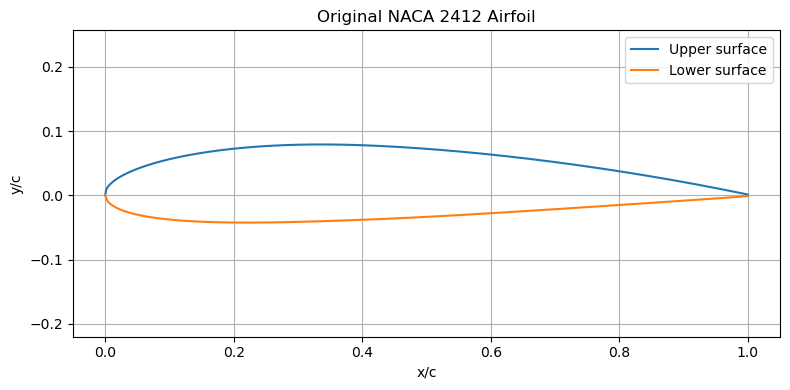

In [3]:
camber_digit = 2
location_digit = 4
thickness_digit = 12

m = camber_digit / 100
p = location_digit / 10
t = thickness_digit / 100
naca_name = f"{camber_digit}{location_digit}{thickness_digit:02d}"

x = np.linspace(0, 1, 400)
xu, yu, xl, yl = naca4(m, p, t, x)

plt.figure(figsize=(8, 4))
plt.plot(xu, yu, label="Upper surface")
plt.plot(xl, yl, label="Lower surface")
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Original NACA {naca_name} Airfoil")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Sample Points

Twelve equally spaced sample stations are selected between x/c = 0 and x/c = 1. The NACA 2412 equations are evaluated at these stations to obtain the upper and lower surface ordinates used by both interpolation methods.

In [4]:
x_sample = np.linspace(0, 1, 12)
xu_s, yu_s, xl_s, yl_s = naca4(m, p, t, x_sample)

print("Airfoil:", f"NACA {naca_name}")
print("Number of sample points:", len(x_sample))

Airfoil: NACA 2412
Number of sample points: 12


## 8. Lagrange Interpolation

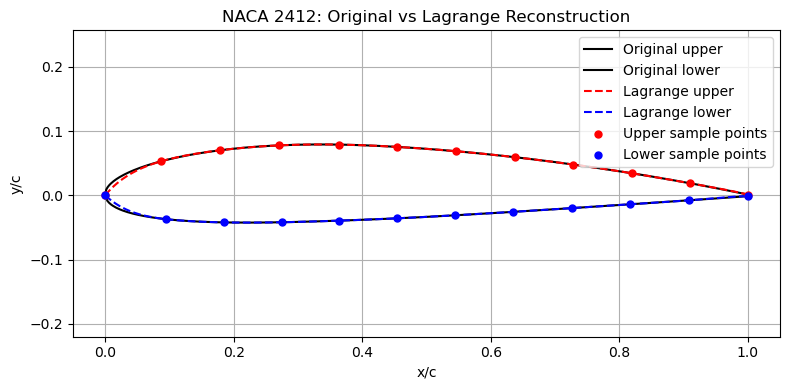

In [5]:
def Lagrng(x, y, n, z):

    total = 0.0

    for i in range(n):

        product = y[i]

        for j in range(n):

            if i != j:
                product = product * (
                    (z - x[j]) / (x[i] - x[j])
                )

        total = total + product

    return total


x_fine = np.linspace(x_sample[0], x_sample[-1], 400)
n = len(x_sample)

xu_rec = []
yu_rec = []
xl_rec = []
yl_rec = []

for z in x_fine:
    xu_rec.append(Lagrng(x_sample, xu_s, n, z))
    yu_rec.append(Lagrng(x_sample, yu_s, n, z))
    xl_rec.append(Lagrng(x_sample, xl_s, n, z))
    yl_rec.append(Lagrng(x_sample, yl_s, n, z))

xu_rec = np.array(xu_rec)
yu_rec = np.array(yu_rec)
xl_rec = np.array(xl_rec)
yl_rec = np.array(yl_rec)

plt.figure(figsize=(8, 4))
plt.plot(xu, yu, "k-", label="Original upper")
plt.plot(xl, yl, "k-", label="Original lower")
plt.plot(xu_rec, yu_rec, "r--", label="Lagrange upper")
plt.plot(xl_rec, yl_rec, "b--", label="Lagrange lower")
plt.scatter(xu_s, yu_s, color="red", s=25, label="Upper sample points", zorder=3)
plt.scatter(xl_s, yl_s, color="blue", s=25, label="Lower sample points", zorder=3)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"NACA {naca_name}: Original vs Lagrange Reconstruction")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Lagrange interpolation error

In [6]:
_, yu_reference, _, yl_reference = naca4(m, p, t, x_fine)

error_upper = yu_reference - yu_rec
error_lower = yl_reference - yl_rec

max_error_upper_lag = np.max(np.abs(error_upper))
max_error_lower_lag = np.max(np.abs(error_lower))
rms_upper_lag = np.sqrt(np.mean(error_upper**2))
rms_lower_lag = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))
max_error_combined_lag = np.max(np.abs(all_errors))
rms_combined_lag = np.sqrt(np.mean(all_errors**2))

print(f"NACA Airfoil: {naca_name}")
print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper_lag:.5f}")
print(f"RMS error: {rms_upper_lag:.5f}")
print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower_lag:.5f}")
print(f"RMS error: {rms_lower_lag:.5f}")
print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined_lag:.5f}")
print(f"RMS error: {rms_combined_lag:.5f}")

NACA Airfoil: 2412

UPPER SURFACE
Maximum absolute error: 0.00804
RMS error: 0.00136

LOWER SURFACE
Maximum absolute error: 0.00693
RMS error: 0.00105

COMBINED AIRFOIL
Maximum absolute error: 0.00804
RMS error: 0.00122


## 9. Natural Cubic Spline Interpolation

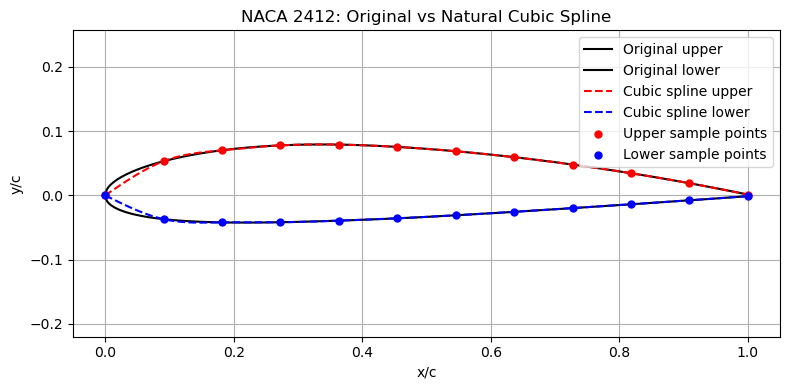

In [7]:
def calculate_spline_derivatives(x_data, y_data):

    n = len(x_data)

    if n < 3:
        raise ValueError("At least 3 sample points are required.")

    if len(y_data) != n:
        raise ValueError("x_data and y_data must have equal lengths.")

    if np.any(np.diff(x_data) <= 0):
        raise ValueError("x_data must be strictly increasing.")

    h = np.diff(x_data)

    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2)

    for i in range(1, n - 1):

        row = i - 1

        b[row] = 6 * (
            (y_data[i + 1] - y_data[i]) / h[i]
            - (y_data[i] - y_data[i - 1]) / h[i - 1]
        )

        A[row, row] = 2 * (h[i - 1] + h[i])

        if i > 1:
            A[row, row - 1] = h[i - 1]

        if i < n - 2:
            A[row, row + 1] = h[i]

    M_inner = np.linalg.solve(A, b)

    # Natural spline boundary conditions
    M = np.zeros(n)
    M[1:-1] = M_inner

    return h, M


def cubic_spline_value(x_data, y_data, h, M, xq):

    if xq < x_data[0] or xq > x_data[-1]:
        raise ValueError("Query point is outside the sample range.")

    i = np.searchsorted(x_data, xq) - 1
    i = max(0, min(i, len(x_data) - 2))

    term1 = (
        M[i] * (x_data[i + 1] - xq)**3
        / (6 * h[i])
    )

    term2 = (
        M[i + 1] * (xq - x_data[i])**3
        / (6 * h[i])
    )

    term3 = (
        (y_data[i] - M[i] * h[i]**2 / 6)
        * (x_data[i + 1] - xq) / h[i]
    )

    term4 = (
        (y_data[i + 1] - M[i + 1] * h[i]**2 / 6)
        * (xq - x_data[i]) / h[i]
    )

    return term1 + term2 + term3 + term4


h_upper, M_upper = calculate_spline_derivatives(x_sample, yu_s)
h_lower, M_lower = calculate_spline_derivatives(x_sample, yl_s)

yu_spline = np.array([
    cubic_spline_value(x_sample, yu_s, h_upper, M_upper, z)
    for z in x_fine
])

yl_spline = np.array([
    cubic_spline_value(x_sample, yl_s, h_lower, M_lower, z)
    for z in x_fine
])

plt.figure(figsize=(8, 4))
plt.plot(x, yu, "k-", label="Original upper")
plt.plot(x, yl, "k-", label="Original lower")
plt.plot(x_fine, yu_spline, "r--", label="Cubic spline upper")
plt.plot(x_fine, yl_spline, "b--", label="Cubic spline lower")
plt.scatter(x_sample, yu_s, color="red", s=25, label="Upper sample points", zorder=3)
plt.scatter(x_sample, yl_s, color="blue", s=25, label="Lower sample points", zorder=3)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"NACA {naca_name}: Original vs Natural Cubic Spline")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Natural cubic spline interpolation error

In [8]:
_, yu_reference, _, yl_reference = naca4(m, p, t, x_fine)

error_upper = yu_reference - yu_spline
error_lower = yl_reference - yl_spline

max_error_upper_spl = np.max(np.abs(error_upper))
max_error_lower_spl = np.max(np.abs(error_lower))
rms_upper_spl = np.sqrt(np.mean(error_upper**2))
rms_lower_spl = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))
max_error_combined_spl = np.max(np.abs(all_errors))
rms_combined_spl = np.sqrt(np.mean(all_errors**2))

print(f"NACA Airfoil: {naca_name}")
print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper_spl:.5f}")
print(f"RMS error: {rms_upper_spl:.5f}")
print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower_spl:.5f}")
print(f"RMS error: {rms_lower_spl:.5f}")
print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined_spl:.5f}")
print(f"RMS error: {rms_combined_spl:.5f}")

NACA Airfoil: 2412

UPPER SURFACE
Maximum absolute error: 0.01187
RMS error: 0.00245

LOWER SURFACE
Maximum absolute error: 0.01171
RMS error: 0.00241

COMBINED AIRFOIL
Maximum absolute error: 0.01187
RMS error: 0.00243


## 10. Error Analysis and Order of Convergence

The convergence test is carried out for NACA 2412 using 4 to 16 equally spaced sample points. For each point count, the upper and lower surface ordinates are reconstructed using Lagrange interpolation and natural cubic spline interpolation.

The combined RMS error is calculated against the NACA equations evaluated on a fine grid. The sample spacing is h = 1/(N − 1), where N is the number of sample points. The empirical order of convergence is estimated by fitting a straight line to log(error) against log(h). The fitted slope is the reported empirical order.

NACA 2412 convergence study
Points    Spacing        Lagrange RMS error    Spline RMS error
     4    0.333333       0.00727730          0.00979679
     5    0.250000       0.00460908          0.00703330
     6    0.200000       0.00339114          0.00553717
     7    0.166667       0.00265641          0.00456357
     8    0.142857       0.00216298          0.00388440
     9    0.125000       0.00181342          0.00338167
    10    0.111111       0.00155643          0.00299488
    11    0.100000       0.00135629          0.00268794
    12    0.090909       0.00122194          0.00243832
    14    0.076923       0.00101931          0.00205679
    16    0.066667       0.00085185          0.00177879

Empirical Lagrange order of convergence: 1.320
Empirical natural cubic spline order: 1.054


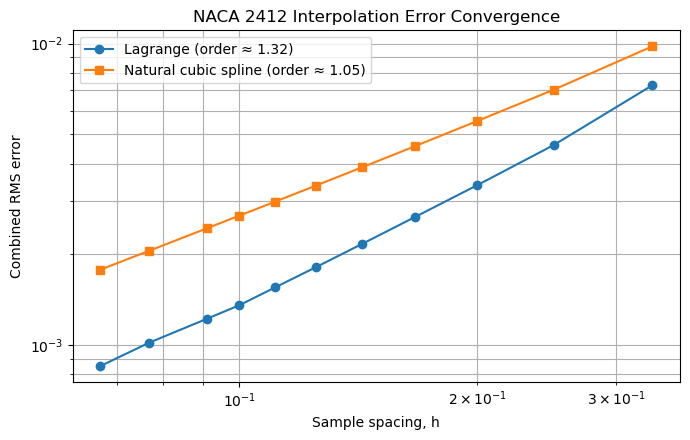

In [9]:
# Error analysis and convergence study for NACA 2412

point_counts = [4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16]
x_fine_convergence = np.linspace(0, 1, 4001)

# Reference upper and lower surface from the NACA 2412 equations
_, yu_exact, _, yl_exact = naca4(m, p, t, x_fine_convergence)

spacing_values = []
lagrange_rms_errors = []
spline_rms_errors = []

for point_count in point_counts:
    x_points = np.linspace(0, 1, point_count)
    _, yu_points, _, yl_points = naca4(m, p, t, x_points)

    # Lagrange interpolation
    yu_lagrange = np.array([
        Lagrng(x_points, yu_points, point_count, z)
        for z in x_fine_convergence
    ])
    yl_lagrange = np.array([
        Lagrng(x_points, yl_points, point_count, z)
        for z in x_fine_convergence
    ])

    lagrange_error = np.concatenate((
        yu_exact - yu_lagrange,
        yl_exact - yl_lagrange
    ))
    lagrange_rms = np.sqrt(np.mean(lagrange_error**2))

    # Natural cubic spline interpolation
    h_upper_test, M_upper_test = calculate_spline_derivatives(
        x_points, yu_points
    )
    h_lower_test, M_lower_test = calculate_spline_derivatives(
        x_points, yl_points
    )

    yu_spline_test = np.array([
        cubic_spline_value(
            x_points, yu_points, h_upper_test, M_upper_test, z
        )
        for z in x_fine_convergence
    ])
    yl_spline_test = np.array([
        cubic_spline_value(
            x_points, yl_points, h_lower_test, M_lower_test, z
        )
        for z in x_fine_convergence
    ])

    spline_error = np.concatenate((
        yu_exact - yu_spline_test,
        yl_exact - yl_spline_test
    ))
    spline_rms = np.sqrt(np.mean(spline_error**2))

    spacing_values.append(1 / (point_count - 1))
    lagrange_rms_errors.append(lagrange_rms)
    spline_rms_errors.append(spline_rms)

# Estimate empirical convergence orders from the log-log slopes
lagrange_order = np.polyfit(
    np.log(spacing_values), np.log(lagrange_rms_errors), 1
)[0]
spline_order = np.polyfit(
    np.log(spacing_values), np.log(spline_rms_errors), 1
)[0]

print("NACA 2412 convergence study")
print("Points    Spacing        Lagrange RMS error    Spline RMS error")
for i in range(len(point_counts)):
    print(
        f"{point_counts[i]:>6}    "
        f"{spacing_values[i]:.6f}       "
        f"{lagrange_rms_errors[i]:.8f}          "
        f"{spline_rms_errors[i]:.8f}"
    )

print()
print(f"Empirical Lagrange order of convergence: {lagrange_order:.3f}")
print(f"Empirical natural cubic spline order: {spline_order:.3f}")

# One line graph: RMS error against sample spacing
plt.figure(figsize=(7, 4.5))
plt.loglog(
    spacing_values, lagrange_rms_errors, "o-",
    label=f"Lagrange (order ≈ {lagrange_order:.2f})"
)
plt.loglog(
    spacing_values, spline_rms_errors, "s-",
    label=f"Natural cubic spline (order ≈ {spline_order:.2f})"
)
plt.xlabel("Sample spacing, h")
plt.ylabel("Combined RMS error")
plt.title("NACA 2412 Interpolation Error Convergence")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


## 11. Results and Discussion

The NACA 2412 profile was generated using m = 0.02, p = 0.4, and t = 0.12. Twelve equally spaced sample stations were used for the initial reconstruction.

The maximum absolute error and root mean square (RMS) error were calculated for the upper surface, lower surface, and combined profile. The reference ordinates for the error calculations were evaluated directly from the NACA 2412 equations at the query points.

The convergence study compares the RMS interpolation error for different numbers of equally spaced sample points. A log-log line graph is used to estimate the empirical order of convergence. Since Lagrange interpolation uses a single high-degree polynomial, increasing the number of equally spaced points can eventually cause oscillations. Therefore, its convergence trend should be interpreted over the tested range rather than assumed to improve indefinitely.

## 12. Conclusion

The NACA 2412 airfoil was generated and reconstructed using Lagrange interpolation and natural cubic spline interpolation. Maximum absolute error and RMS error were calculated against ordinates evaluated from the NACA airfoil equations.

The convergence study uses the RMS error as the error measure and the spacing between equally spaced sample stations as the resolution measure. The empirical order is estimated from the slope of the log(error) versus log(spacing) graph. The order is specific to the tested point counts and the interpolation setup; it should not be treated as a universal theoretical order for all airfoil profiles or sampling strategies.

## 13. References

1. [https://en.wikipedia.org/wiki/NACA_airfoil]
2. Burden, R. L., and Faires, J. D., Numerical Analysis, chapter on interpolation.
3. [https://numpy.org/]
4. [https://matplotlib.org/]